In [1]:
# Cell 1 — Mount Drive + project paths
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
SRC_DIR     = PROJECT_DIR / "src"
FIG_DIR     = PROJECT_DIR / "reports" / "figures" / "FD001"
TAB_DIR     = PROJECT_DIR / "reports" / "eda" / "FD001"
for p in (SRC_DIR, FIG_DIR, TAB_DIR):
    p.mkdir(parents=True, exist_ok=True)
(SRC_DIR / "__init__.py").touch()     # makes `src` an importable Python package
print("Ready:", PROJECT_DIR)

Mounted at /content/drive
Ready: /content/drive/MyDrive/Predictive_Maintenance_RUL


In [2]:
%%writefile /content/drive/MyDrive/Predictive_Maintenance_RUL/src/data_loader.py
"""
data_loader.py — Loading NASA C-MAPSS files (read-only).

Why this file exists: every notebook (EDA, preprocessing, training) and later the
FastAPI backend must read the data in *exactly* the same way, with the same
column names and order. Putting it in one module avoids copy-paste drift.
"""
from pathlib import Path
import numpy as np
import pandas as pd

DATASETS = ["FD001", "FD002", "FD003", "FD004"]

ID_COLS      = ["engine_id", "cycle"]
SETTING_COLS = [f"op_setting_{i}" for i in range(1, 4)]
SENSOR_COLS  = [f"sensor_{i}" for i in range(1, 22)]
COLUMNS      = ID_COLS + SETTING_COLS + SENSOR_COLS          # 26 columns
FEATURE_CANDIDATES = SETTING_COLS + SENSOR_COLS              # 24 candidate inputs


def load_cmapss_file(path) -> pd.DataFrame:
    """Load a train_/test_ file. Whitespace separator handles trailing spaces."""
    path = Path(path)
    df = pd.read_csv(path, sep=r"\s+", header=None)
    if df.shape[1] != len(COLUMNS):
        raise ValueError(f"{path.name}: expected {len(COLUMNS)} columns, got {df.shape[1]}")
    df.columns = COLUMNS
    df["engine_id"] = df["engine_id"].astype(int)
    df["cycle"] = df["cycle"].astype(int)
    return df


def load_rul_file(path) -> pd.DataFrame:
    """Load an RUL_ file: line i = true RUL of test engine i at its last observed cycle."""
    path = Path(path)
    df = pd.read_csv(path, sep=r"\s+", header=None)
    if df.shape[1] != 1:
        raise ValueError(f"{path.name}: expected 1 column, got {df.shape[1]}")
    df.columns = ["true_rul"]
    df.insert(0, "engine_id", np.arange(1, len(df) + 1))
    return df


def load_dataset(fd: str, raw_dir) -> dict:
    """Return {'train', 'test', 'rul'} DataFrames for one sub-dataset."""
    if fd not in DATASETS:
        raise ValueError(f"Unknown dataset {fd!r}; expected one of {DATASETS}")
    raw_dir = Path(raw_dir)
    return {
        "train": load_cmapss_file(raw_dir / f"train_{fd}.txt"),
        "test":  load_cmapss_file(raw_dir / f"test_{fd}.txt"),
        "rul":   load_rul_file(raw_dir / f"RUL_{fd}.txt"),
    }

Writing /content/drive/MyDrive/Predictive_Maintenance_RUL/src/data_loader.py


In [3]:
# Cell 3 — Imports, plotting style, load FD001
import sys, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(PROJECT_DIR))
import src.data_loader as dl
importlib.reload(dl)                      # picks up edits to the .py file without restarting

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

def save_fig(fig, name):
    """Save a figure to reports/figures/FD001/ at 150 dpi."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

FD = "FD001"
d = dl.load_dataset(FD, RAW_DIR)
train, test = d["train"], d["test"]
FEATURES = dl.FEATURE_CANDIDATES
print(FD, "| train:", train.shape, "| test:", test.shape)

FD001 | train: (20631, 26) | test: (13096, 26)


Training engine lifetimes (cycles until failure):
count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: lifetime_cycles, dtype: float64
Skewness: 1.03


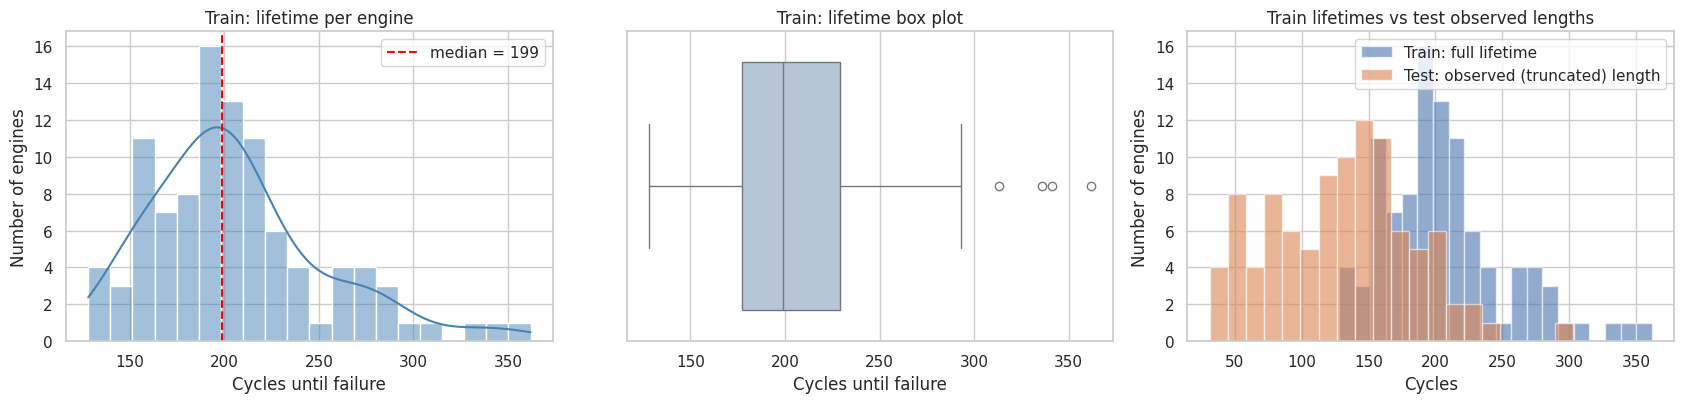

In [4]:
# Cell 4 — How long do engines live before failure?
train_life = train.groupby("engine_id")["cycle"].max().rename("lifetime_cycles")
test_obs   = test.groupby("engine_id")["cycle"].max().rename("observed_cycles")

print("Training engine lifetimes (cycles until failure):")
print(train_life.describe().round(1))
print("Skewness:", round(train_life.skew(), 2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(train_life, bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(train_life.median(), color="red", ls="--", label=f"median = {train_life.median():.0f}")
axes[0].set(title="Train: lifetime per engine", xlabel="Cycles until failure", ylabel="Number of engines")
axes[0].legend()

sns.boxplot(x=train_life, ax=axes[1], color="lightsteelblue")
axes[1].set(title="Train: lifetime box plot", xlabel="Cycles until failure")

axes[2].hist(train_life, bins=20, alpha=0.6, label="Train: full lifetime")
axes[2].hist(test_obs, bins=20, alpha=0.6, label="Test: observed (truncated) length")
axes[2].set(title="Train lifetimes vs test observed lengths", xlabel="Cycles", ylabel="Number of engines")
axes[2].legend()
fig.tight_layout(); save_fig(fig, "01_engine_lifetime_distribution"); plt.show()

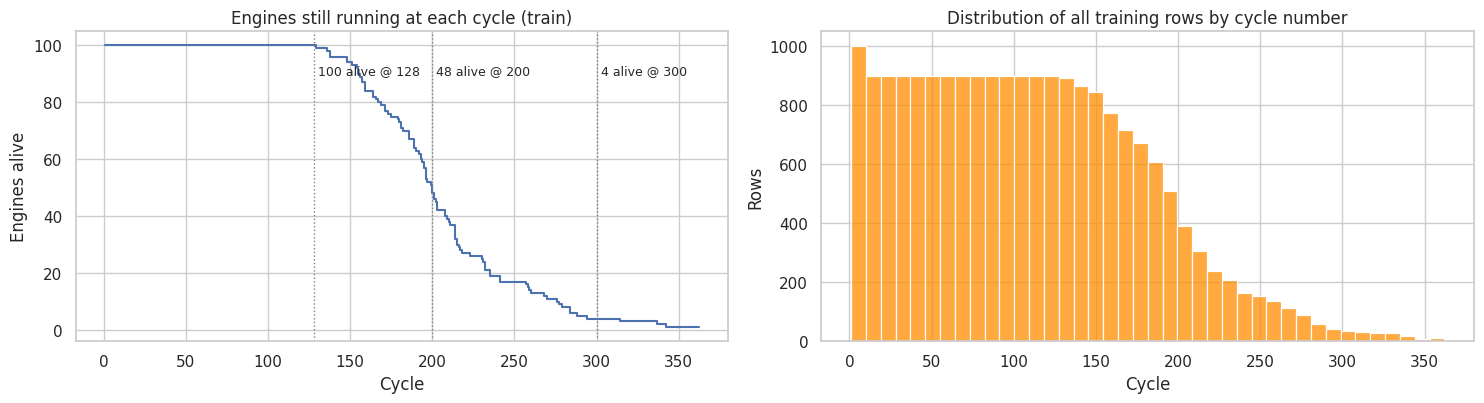

Engines alive at cycle 128 / 200 / 250 / 300: [100, 48, 17, 4]


In [5]:
# Cell 5 — How many engines are still running at each cycle?
max_c = train_life.max()
alive = pd.Series([(train_life >= t).sum() for t in range(1, max_c + 1)],
                  index=range(1, max_c + 1), name="engines_alive")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].step(alive.index, alive.values, where="post")
for q in (128, 200, 300):
    axes[0].axvline(q, color="grey", ls=":", lw=1)
    axes[0].text(q, alive.max() * 0.9, f" {alive.get(q, 0)} alive @ {q}", fontsize=9)
axes[0].set(title="Engines still running at each cycle (train)", xlabel="Cycle", ylabel="Engines alive")

sns.histplot(train["cycle"], bins=40, ax=axes[1], color="darkorange")
axes[1].set(title="Distribution of all training rows by cycle number", xlabel="Cycle", ylabel="Rows")
fig.tight_layout(); save_fig(fig, "02_cycle_coverage"); plt.show()

print("Engines alive at cycle 128 / 200 / 250 / 300:",
      [int(alive.get(c, 0)) for c in (128, 200, 250, 300)])

In [6]:
# Cell 6 — Descriptive statistics for all 24 candidate features
summary = train[FEATURES].describe().T
summary["n_unique"] = train[FEATURES].nunique()
summary["range"]    = summary["max"] - summary["min"]
summary = summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "range", "n_unique"]]
summary.to_csv(TAB_DIR / "feature_summary.csv")
display(summary.style.format("{:.4f}").background_gradient(subset=["std"], cmap="Blues"))

,count,mean,std,min,25%,50%,75%,max,range,n_unique
op_setting_1,20631.0000,-0.0000,0.0022,-0.0087,-0.0015,0.0000,0.0015,0.0087,0.0174,158.0000
op_setting_2,20631.0000,0.0000,0.0003,-0.0006,-0.0002,0.0000,0.0003,0.0006,0.0012,13.0000
op_setting_3,20631.0000,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000,0.0000,1.0000
sensor_1,20631.0000,518.6700,0.0000,518.6700,518.6700,518.6700,518.6700,518.6700,0.0000,1.0000
sensor_2,20631.0000,642.6809,0.5001,641.2100,642.3250,642.6400,643.0000,644.5300,3.3200,310.0000
sensor_3,20631.0000,1590.5231,6.1311,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100,45.8700,3012.0000
sensor_4,20631.0000,1408.9338,9.0006,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900,59.2400,4051.0000
sensor_5,20631.0000,14.6200,0.0000,14.6200,14.6200,14.6200,14.6200,14.6200,0.0000,1.0000
sensor_6,20631.0000,21.6098,0.0014,21.6000,21.6100,21.6100,21.6100,21.6100,0.0100,2.0000
sensor_7,20631.0000,553.3677,0.8851,549.8500,552.8100,553.4400,554.0100,556.0600,6.2100,513.0000


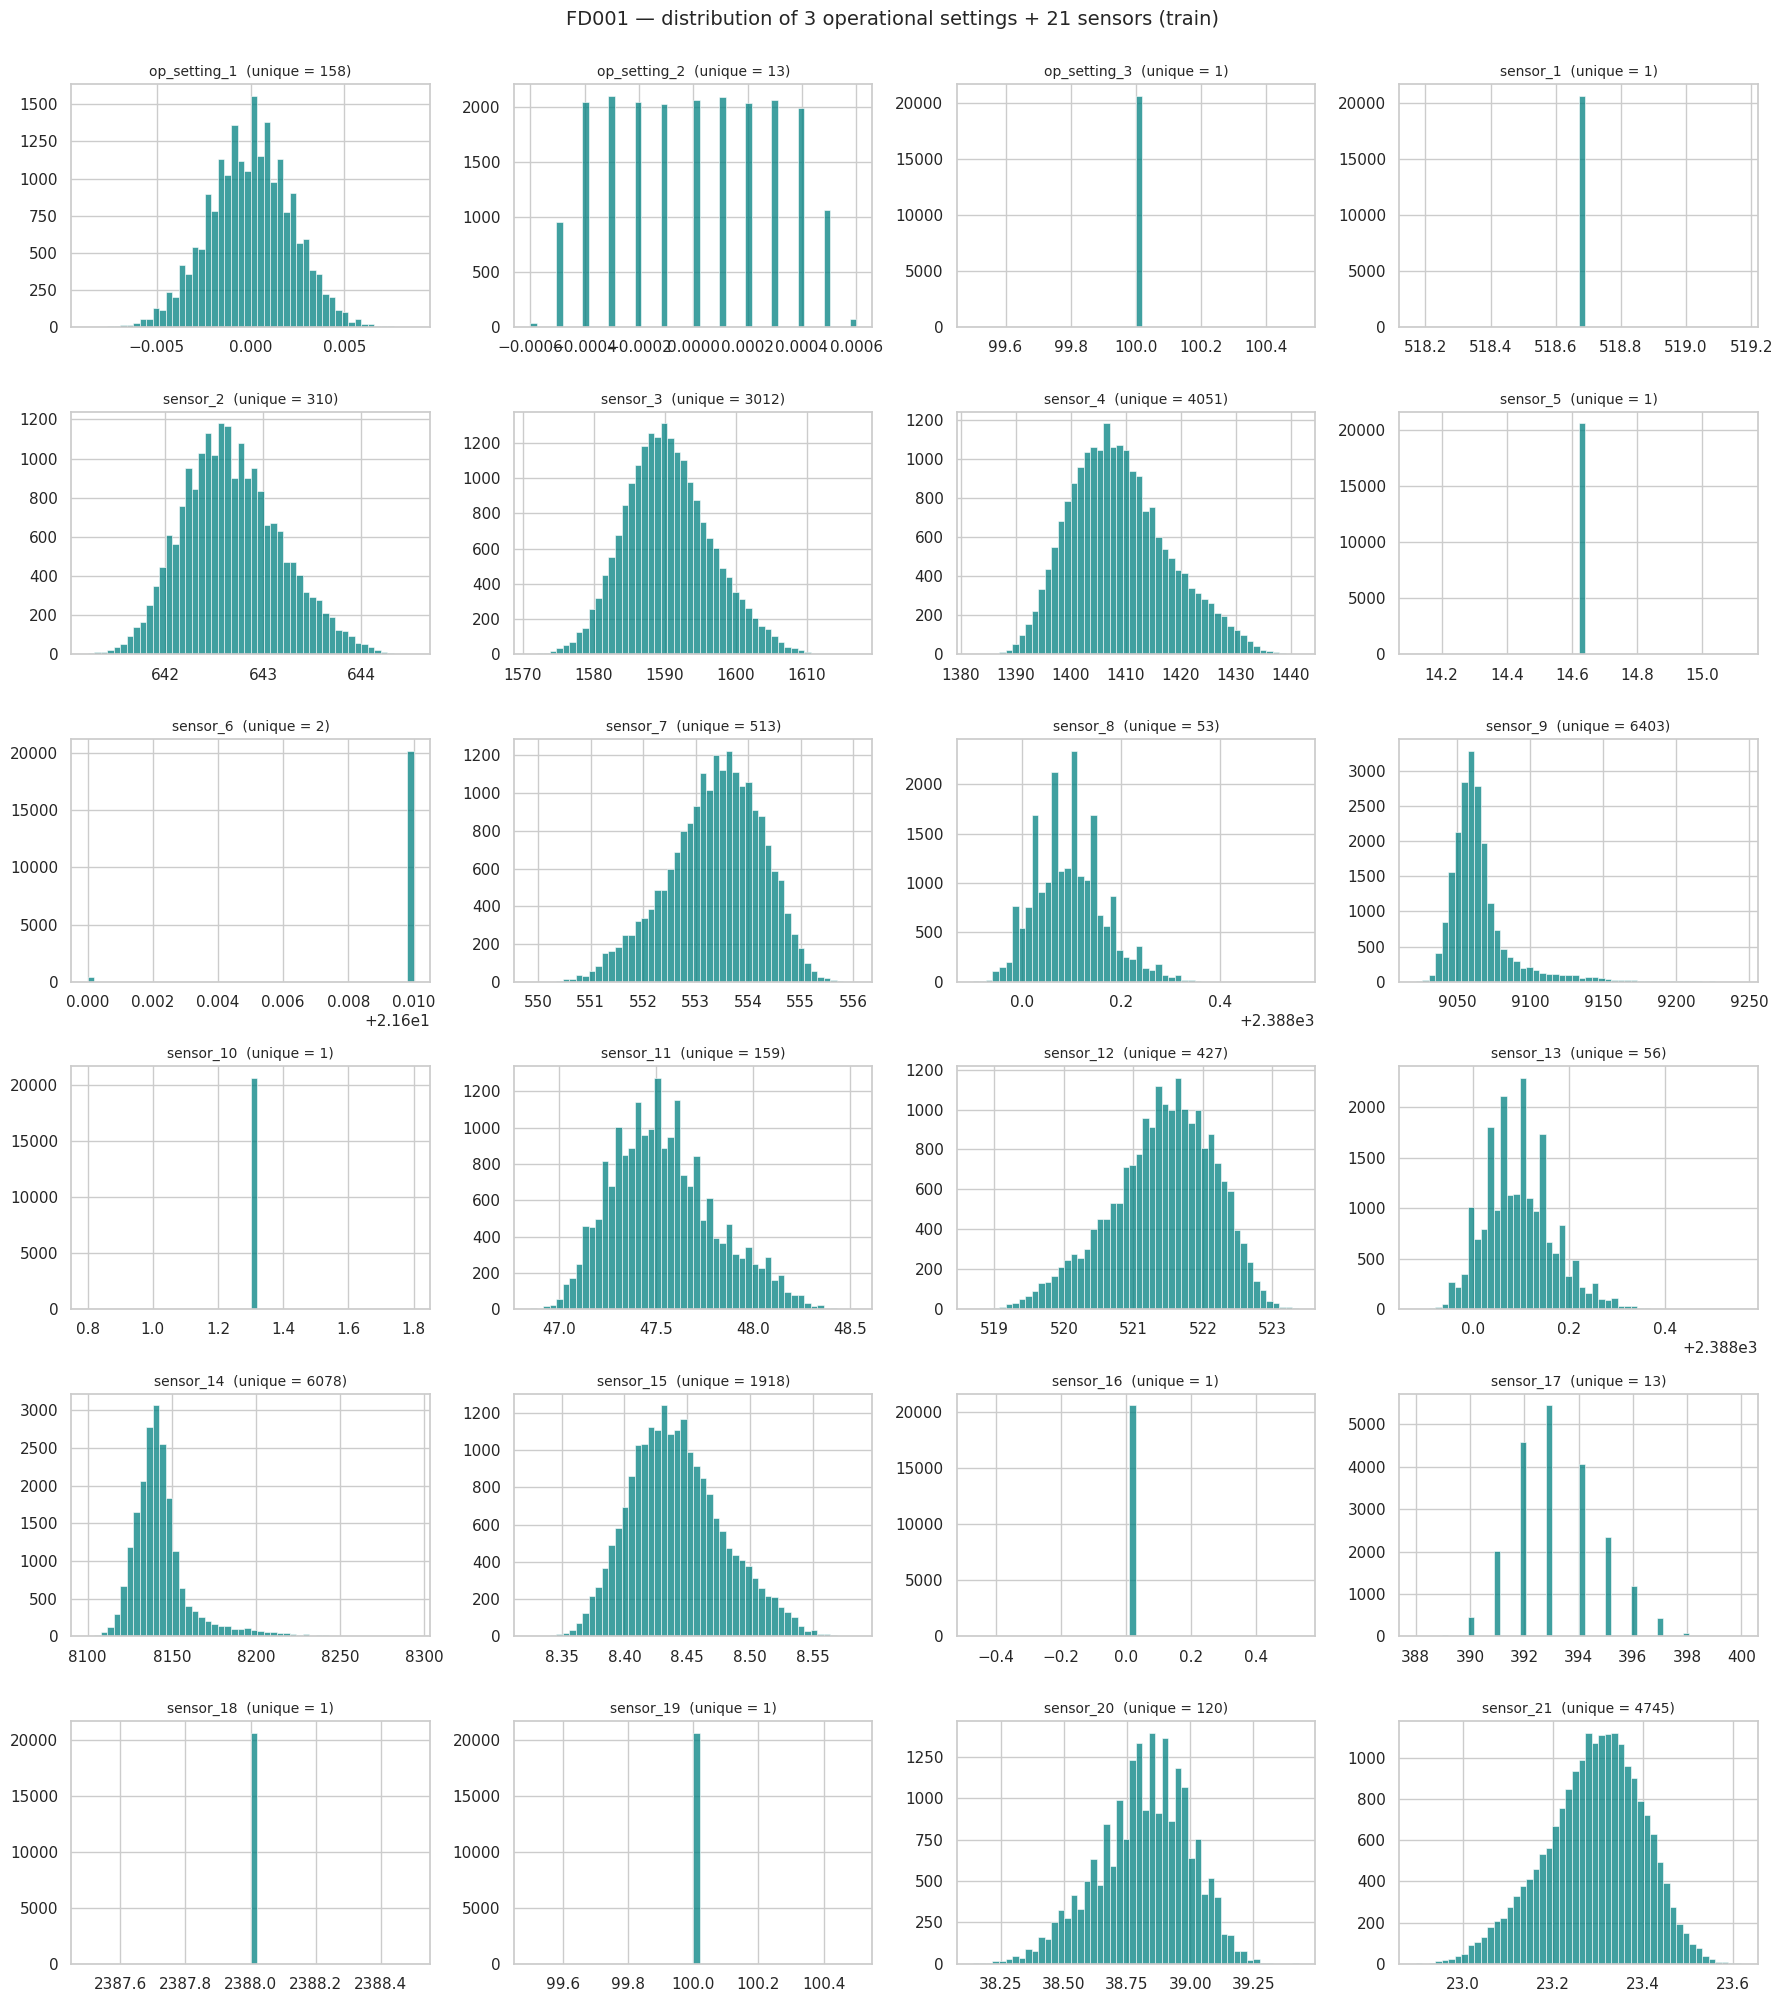

In [7]:
# Cell 7 — Histogram of every candidate feature
fig, axes = plt.subplots(6, 4, figsize=(18, 20))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(train[col], bins=50, ax=ax, color="teal")
    ax.set_title(f"{col}  (unique = {train[col].nunique()})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("FD001 — distribution of 3 operational settings + 21 sensors (train)", y=1.0, fontsize=14)
fig.tight_layout(); save_fig(fig, "03_feature_distributions"); plt.show()

,std,n_unique,range,flag
op_setting_3,0.000000e+00,1,0.0000,CONSTANT
sensor_19,0.000000e+00,1,0.0000,CONSTANT
sensor_18,0.000000e+00,1,0.0000,CONSTANT
sensor_16,1.556432e-14,1,0.0000,CONSTANT
sensor_10,4.660829e-13,1,0.0000,CONSTANT
sensor_5,3.394700e-12,1,0.0000,CONSTANT
sensor_1,6.537152e-11,1,0.0000,CONSTANT
op_setting_2,2.930621e-04,13,0.0012,variable
sensor_6,1.388985e-03,2,0.0100,NEAR-CONSTANT
op_setting_1,2.187313e-03,158,0.0174,variable


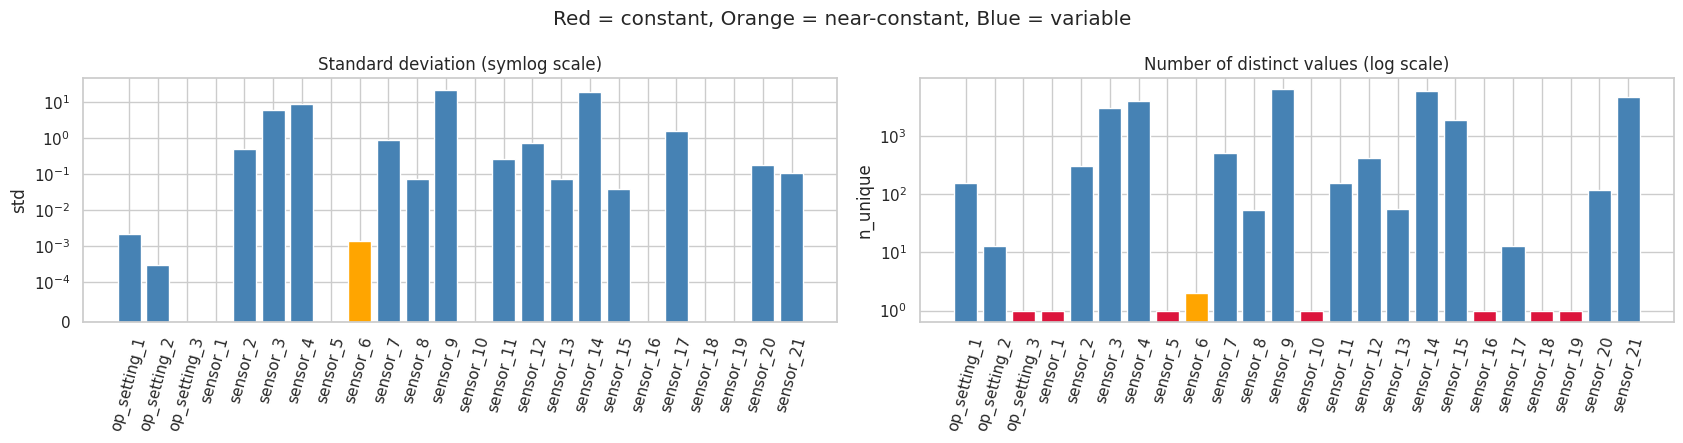

CONSTANT:      ['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
NEAR-CONSTANT: ['sensor_6']


In [9]:
# Cell 8 — Which features carry (almost) no information?
var_df = pd.DataFrame({
    "std":      train[FEATURES].std(),
    "n_unique": train[FEATURES].nunique(),
    "range":    train[FEATURES].max() - train[FEATURES].min(),
})
var_df["flag"] = np.select(
    [var_df["n_unique"] == 1,          # exactly one value → constant (robust to float rounding)
     var_df["n_unique"] <= 2],         # two values → near-constant
    ["CONSTANT", "NEAR-CONSTANT"], default="variable")
var_df.to_csv(TAB_DIR / "variance_report.csv")
display(var_df.sort_values("std"))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
colors = var_df["flag"].map({"CONSTANT": "crimson", "NEAR-CONSTANT": "orange", "variable": "steelblue"})
axes[0].bar(var_df.index, var_df["std"], color=colors)
axes[0].set_yscale("symlog", linthresh=1e-4)
axes[0].set(title="Standard deviation (symlog scale)", ylabel="std")
axes[1].bar(var_df.index, var_df["n_unique"], color=colors)
axes[1].set_yscale("log")
axes[1].set(title="Number of distinct values (log scale)", ylabel="n_unique")
for ax in axes:
    ax.tick_params(axis="x", rotation=75)
fig.suptitle("Red = constant, Orange = near-constant, Blue = variable")
fig.tight_layout(); save_fig(fig, "04_variance_analysis"); plt.show()

print("CONSTANT:     ", var_df.index[var_df.flag == "CONSTANT"].tolist())
print("NEAR-CONSTANT:", var_df.index[var_df.flag == "NEAR-CONSTANT"].tolist())

In [10]:
# Cell 9 — EDA-only RUL column + the 16 "variable" features from Cell 8
eda = train.copy()                                   # work on a copy; `train` stays untouched
eda["RUL"] = eda.groupby("engine_id")["cycle"].transform("max") - eda["cycle"]

var_df = pd.read_csv(TAB_DIR / "variance_report.csv", index_col=0)   # saved by Cell 8
VARIABLE = var_df.index[var_df["flag"] == "variable"].tolist()
print(len(VARIABLE), "variable features:", VARIABLE)

16 variable features: ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


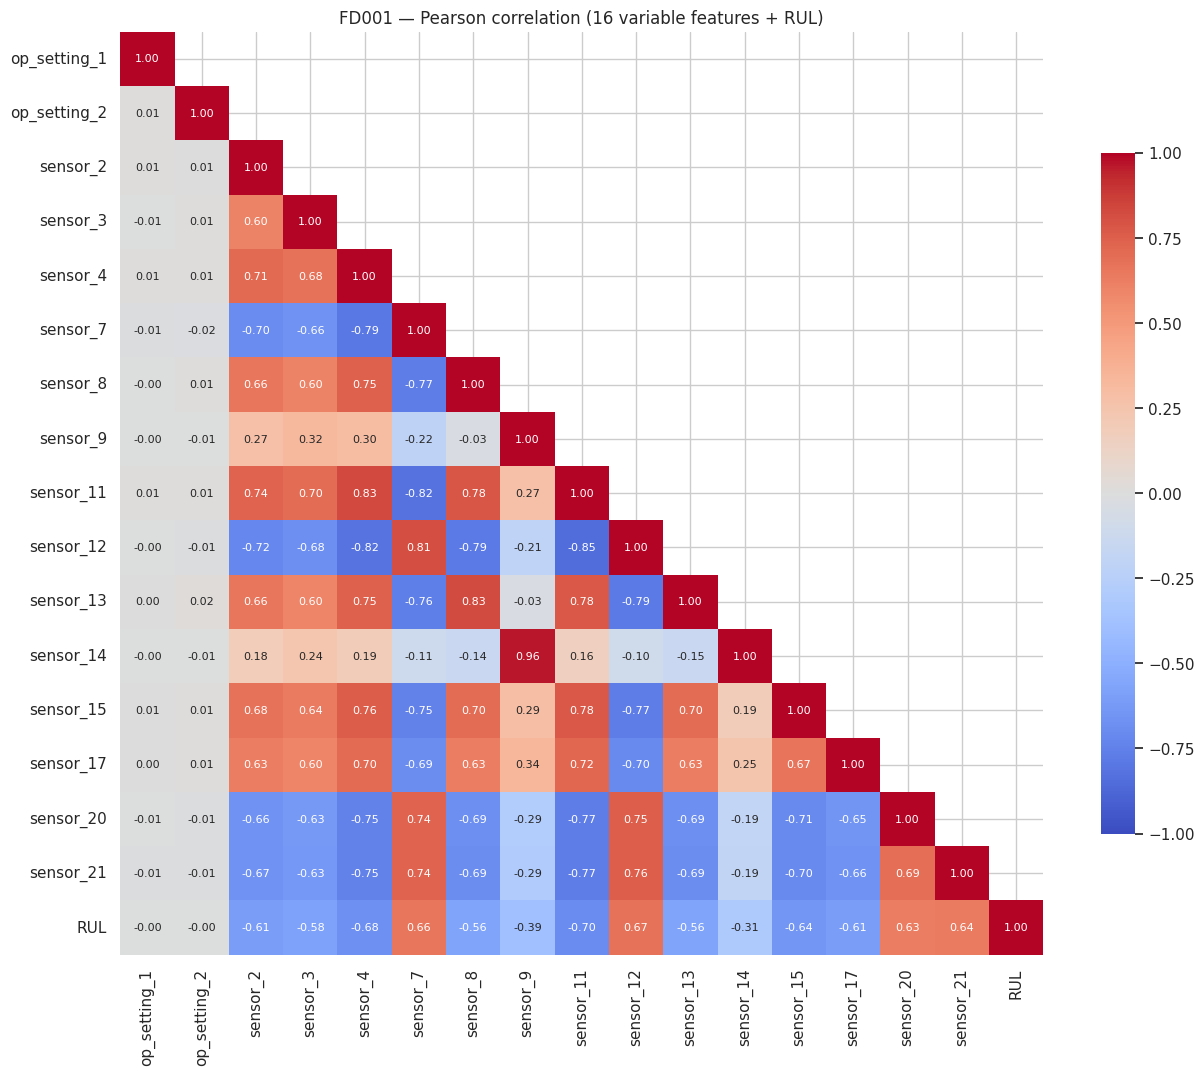

,pearson,spearman
sensor_11,-0.696,-0.718
sensor_4,-0.679,-0.702
sensor_15,-0.643,-0.666
sensor_2,-0.606,-0.629
sensor_17,-0.606,-0.629
sensor_3,-0.585,-0.606
sensor_8,-0.564,-0.574
sensor_13,-0.563,-0.573
sensor_9,-0.390,-0.322
sensor_14,-0.307,-0.202


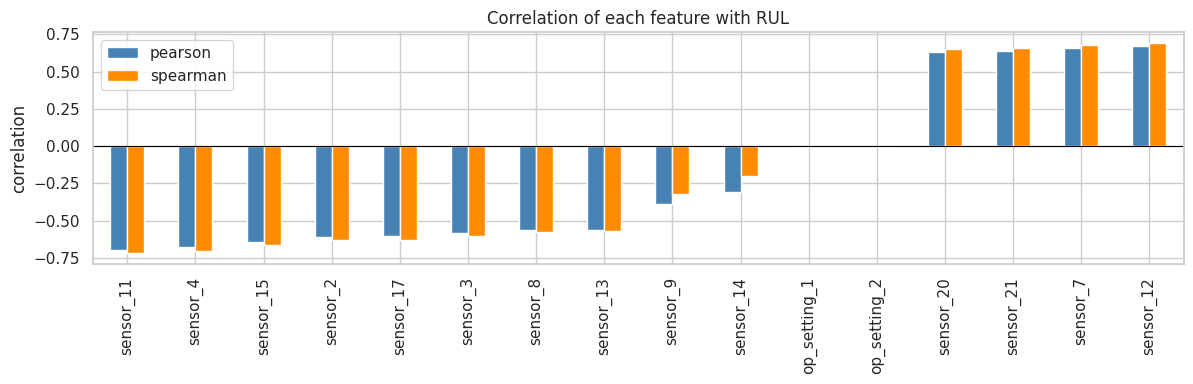

Highly correlated pairs (|r| > 0.8):
   ('sensor_4', 'sensor_11', np.float64(0.83))
   ('sensor_4', 'sensor_12', np.float64(-0.816))
   ('sensor_7', 'sensor_11', np.float64(-0.823))
   ('sensor_7', 'sensor_12', np.float64(0.813))
   ('sensor_8', 'sensor_13', np.float64(0.826))
   ('sensor_9', 'sensor_14', np.float64(0.963))
   ('sensor_11', 'sensor_12', np.float64(-0.847))


In [11]:
# Cell 10 — Feature–feature and feature–RUL correlation
cols = VARIABLE + ["RUL"]
corr = eda[cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)          # hide the duplicate upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, annot_kws={"size": 8}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("FD001 — Pearson correlation (16 variable features + RUL)")
fig.tight_layout(); save_fig(fig, "05_correlation_heatmap"); plt.show()

rul_corr = pd.DataFrame({
    "pearson":  corr["RUL"].drop("RUL"),
    "spearman": eda[cols].corr(method="spearman")["RUL"].drop("RUL"),
}).sort_values("pearson")
rul_corr.to_csv(TAB_DIR / "correlation_with_rul.csv")
display(rul_corr.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
rul_corr.plot.bar(ax=ax, color=["steelblue", "darkorange"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Correlation of each feature with RUL", ylabel="correlation")
fig.tight_layout(); save_fig(fig, "06_correlation_with_rul"); plt.show()

pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(VARIABLE)
         for b in VARIABLE[i + 1:] if abs(corr.loc[a, b]) > 0.8]
print("Highly correlated pairs (|r| > 0.8):")
for p in pairs: print("  ", p)

Sample engines: [9, 10, 20, 42, 61, 69, 72, 83, 95, 97]


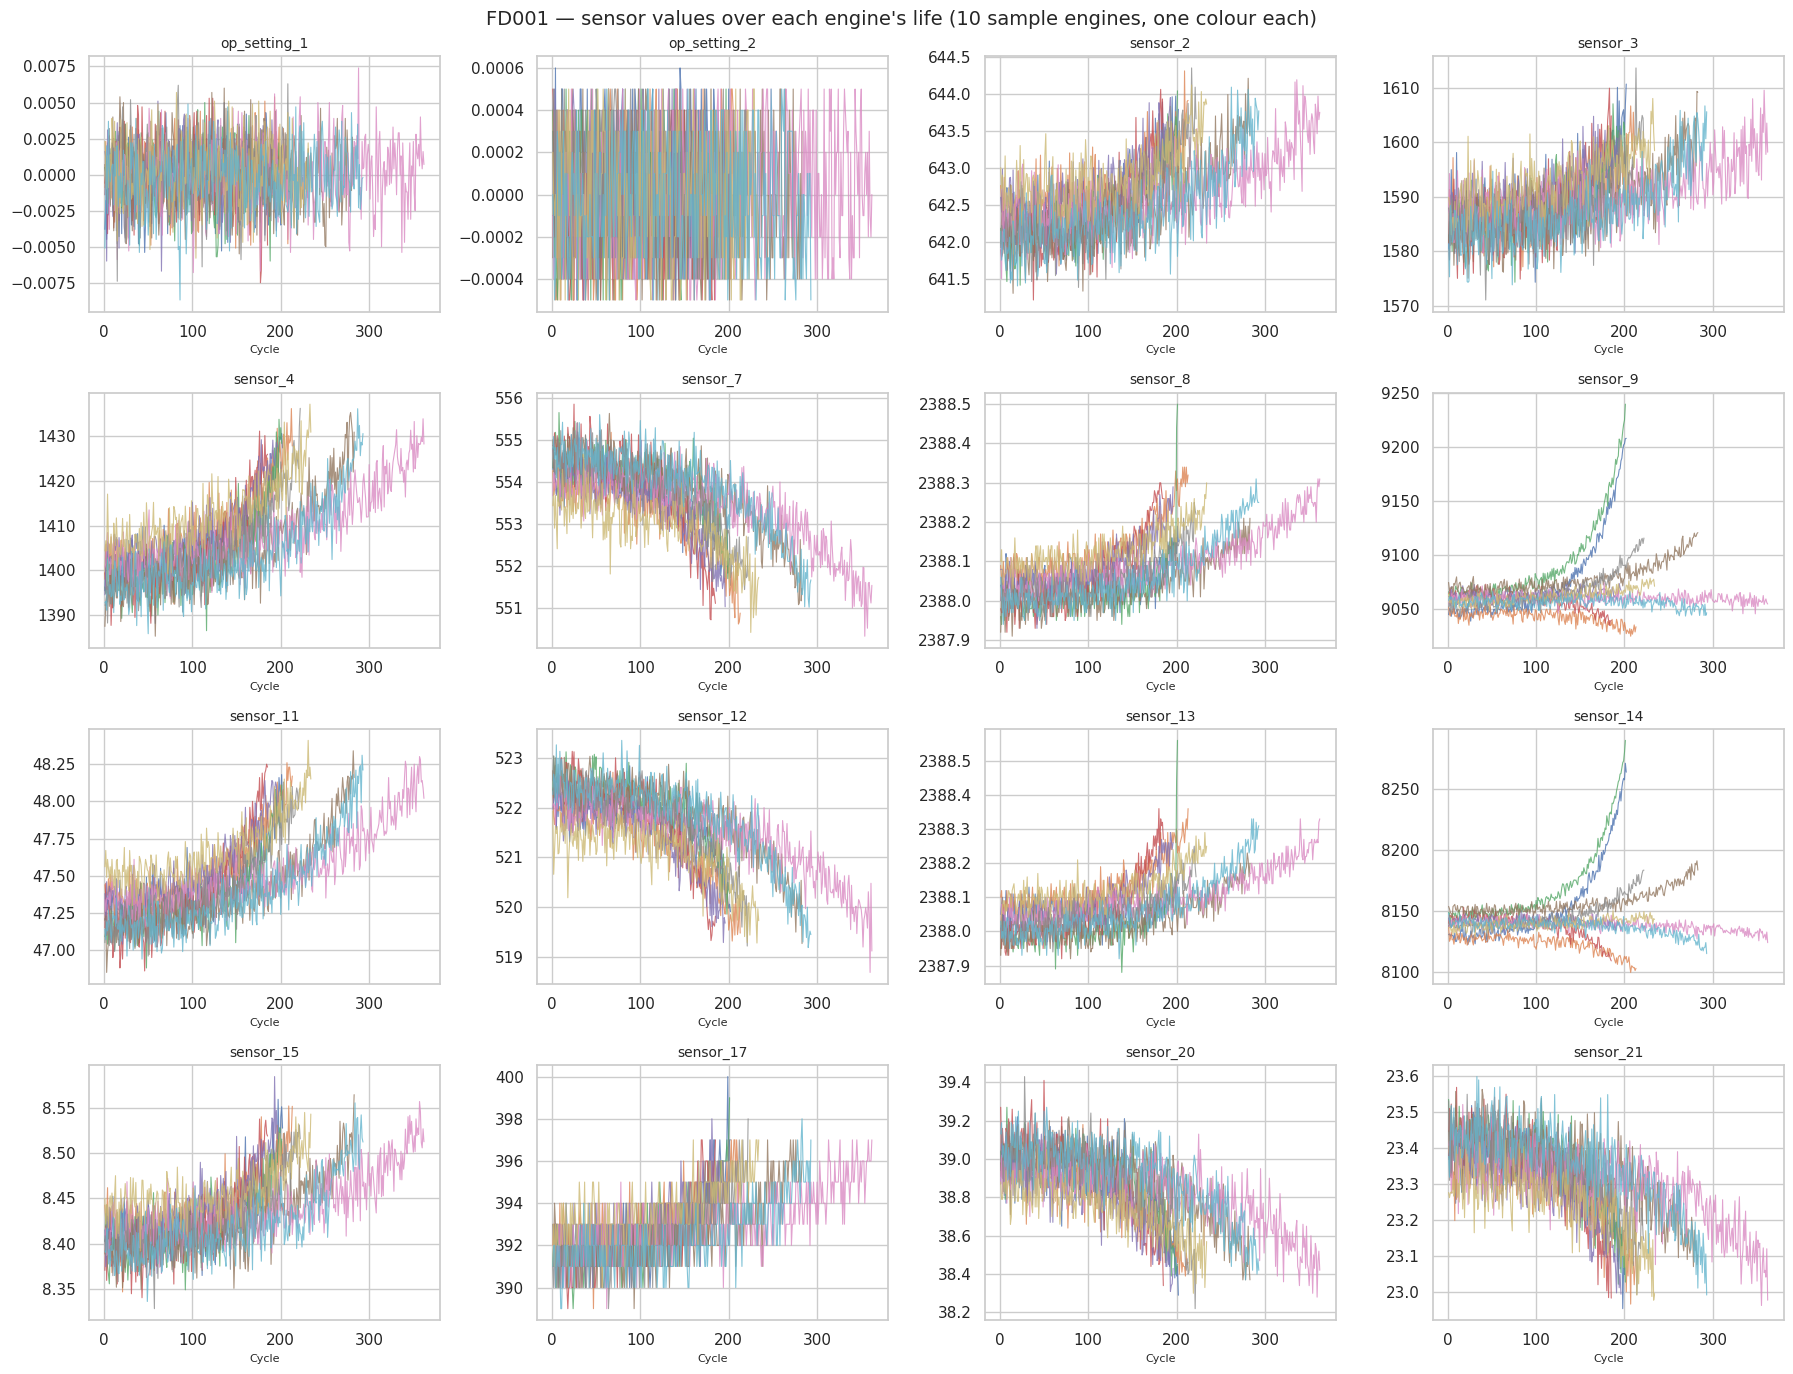

In [12]:
# Cell 11 — Raw trajectories of 10 random engines (seeded → reproducible)
rng = np.random.default_rng(42)
sample_ids = rng.choice(eda["engine_id"].unique(), size=10, replace=False)
print("Sample engines:", sorted(sample_ids.tolist()))

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, VARIABLE):
    for eid in sample_ids:
        g = eda[eda["engine_id"] == eid]
        ax.plot(g["cycle"], g[col], lw=0.8, alpha=0.8)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Cycle", fontsize=8)
fig.suptitle("FD001 — sensor values over each engine's life (10 sample engines, one colour each)", fontsize=14)
fig.tight_layout(); save_fig(fig, "07_sensor_trends_sample_engines"); plt.show()

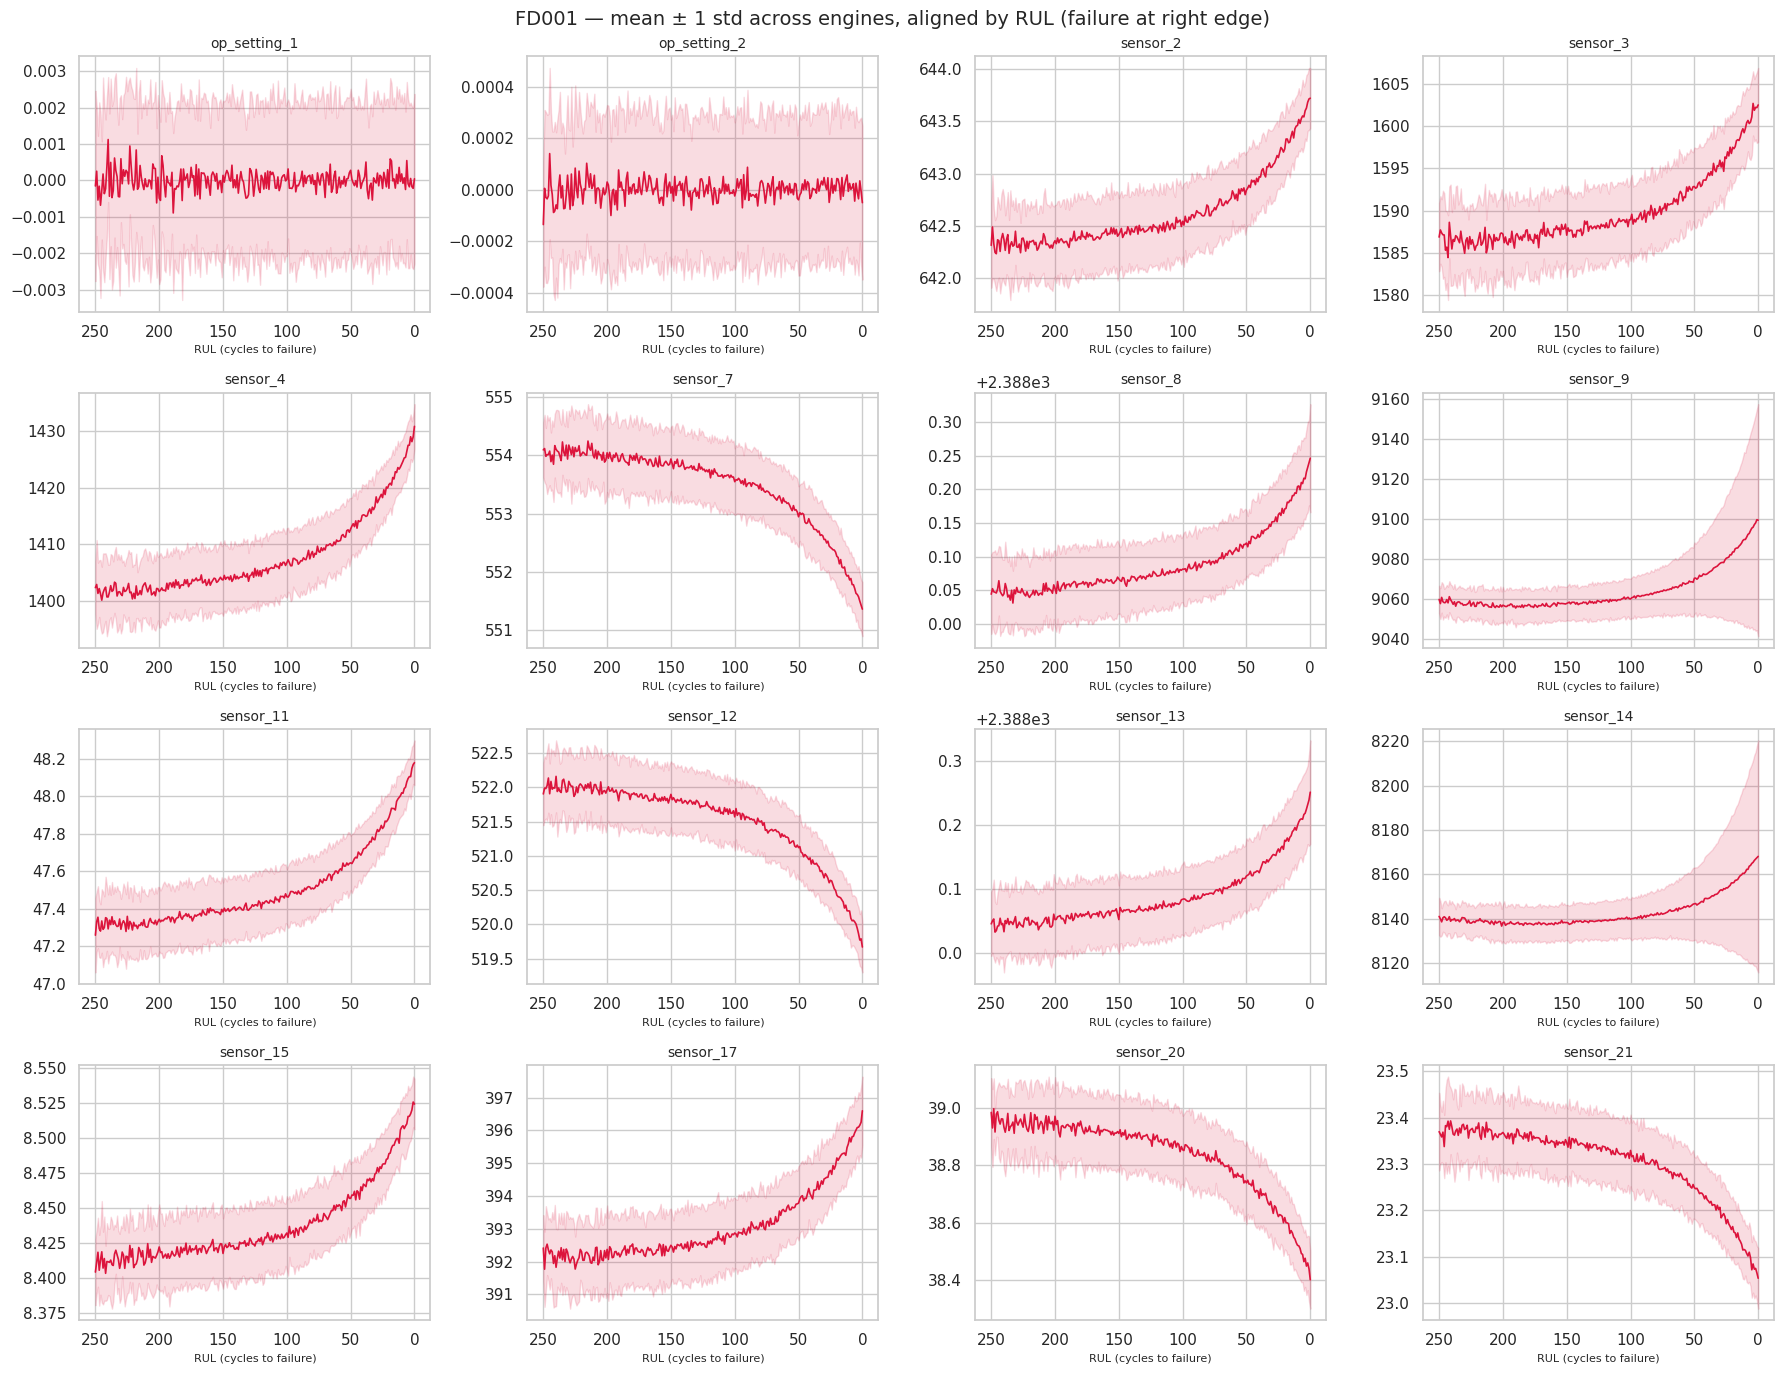

,shift_in_early_std_units,direction
sensor_12,-3.54,falls toward failure
sensor_7,-3.38,falls toward failure
sensor_20,-3.19,falls toward failure
sensor_21,-3.15,falls toward failure
op_setting_1,0.01,rises toward failure
op_setting_2,0.03,rises toward failure
sensor_8,2.63,rises toward failure
sensor_13,2.71,rises toward failure
sensor_2,2.88,rises toward failure
sensor_3,2.88,rises toward failure


,sensor_11,sensor_4,sensor_12
RUL,,,
"(-1, 10]",48.09,1427.10,519.95
"(10, 25]",47.92,1421.21,520.41
"(25, 50]",47.73,1415.41,520.89
"(50, 75]",47.59,1410.36,521.29
"(75, 100]",47.50,1407.50,521.54
"(100, 125]",47.44,1405.70,521.68
"(125, 150]",47.40,1404.21,521.79
"(150, 200]",47.37,1403.22,521.87
"(200, 400]",47.32,1401.66,522.00


In [13]:
# Cell 12 — Average sensor behaviour as engines approach failure
agg = eda[eda["RUL"] <= 250].groupby("RUL")[VARIABLE].agg(["mean", "std"])

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, VARIABLE):
    m, s = agg[(col, "mean")], agg[(col, "std")]
    ax.plot(m.index, m.values, color="crimson", lw=1.2)
    ax.fill_between(m.index, m - s, m + s, color="crimson", alpha=0.15)
    ax.invert_xaxis()                       # left = far from failure, right = failure (RUL 0)
    ax.set_title(col, fontsize=10); ax.set_xlabel("RUL (cycles to failure)", fontsize=8)
fig.suptitle("FD001 — mean ± 1 std across engines, aligned by RUL (failure at right edge)", fontsize=14)
fig.tight_layout(); save_fig(fig, "08_degradation_aligned_by_rul"); plt.show()

# How far does each feature move between early life and the last 20 cycles?
early = eda[eda["cycle"] <= 20][VARIABLE]
late  = eda[eda["RUL"] < 20][VARIABLE]
shift = ((late.mean() - early.mean()) / early.std()).rename("shift_in_early_std_units")
shift = shift.to_frame().assign(direction=np.where(shift > 0, "rises toward failure", "falls toward failure"))
shift.to_csv(TAB_DIR / "degradation_shift.csv")
display(shift.sort_values("shift_in_early_std_units").round(2))

# Is degradation gradual or accelerating? Mean of sensor_11 per RUL band
bands = pd.cut(eda["RUL"], [-1, 10, 25, 50, 75, 100, 125, 150, 200, 400])
display(eda.groupby(bands, observed=True)[["sensor_11", "sensor_4", "sensor_12"]].mean().round(2))

       op_setting_1  op_setting_2  op_setting_3
count   20631.00000   20631.00000       20631.0
mean       -0.00001       0.00000         100.0
std         0.00219       0.00029           0.0
min        -0.00870      -0.00060         100.0
25%        -0.00150      -0.00020         100.0
50%         0.00000       0.00000         100.0
75%         0.00150       0.00030         100.0
max         0.00870       0.00060         100.0

Distinct operating regimes: 1


,op_setting_1,op_setting_2,op_setting_3
0,-0.0,-0.0,100.0


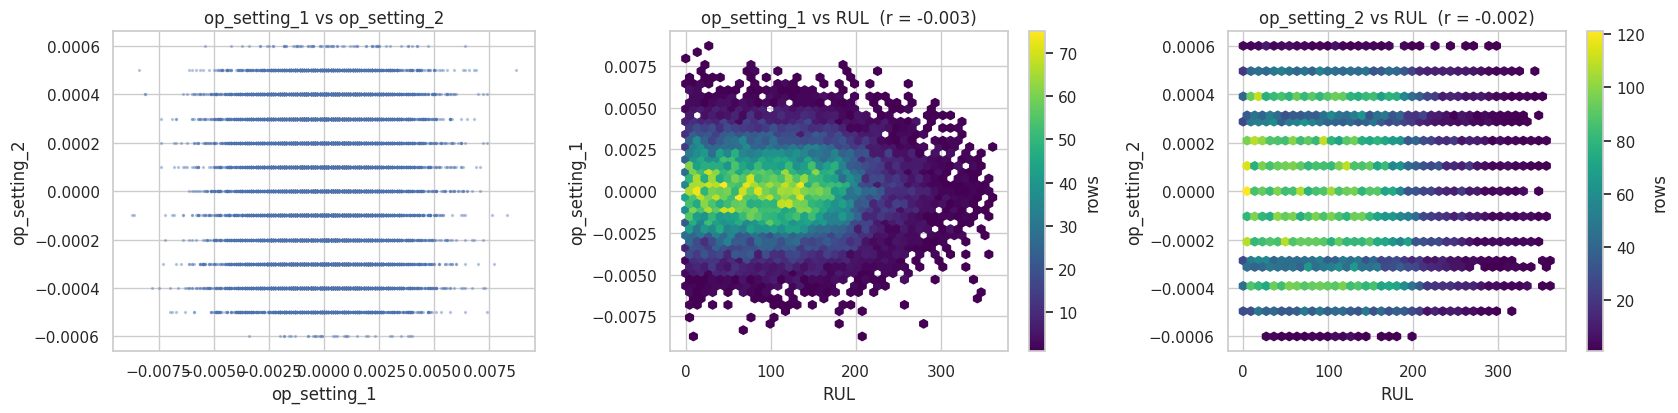

In [14]:
# Cell 13 — Are the operational settings informative in FD001?
SETTINGS = dl.SETTING_COLS
print(eda[SETTINGS].describe().round(5))

# Regime count: round settings to a coarse grid and count distinct combinations.
# (Reusable for FD002/FD004, where 6 regimes are expected.)
regimes = eda[SETTINGS].round({"op_setting_1": 0, "op_setting_2": 2, "op_setting_3": 0}).drop_duplicates()
print("\nDistinct operating regimes:", len(regimes)); display(regimes)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].scatter(eda["op_setting_1"], eda["op_setting_2"], s=2, alpha=0.3)
axes[0].set(title="op_setting_1 vs op_setting_2", xlabel="op_setting_1", ylabel="op_setting_2")
for ax, col in zip(axes[1:], ["op_setting_1", "op_setting_2"]):
    hb = ax.hexbin(eda["RUL"], eda[col], gridsize=40, cmap="viridis", mincnt=1)
    ax.set(title=f"{col} vs RUL  (r = {eda[col].corr(eda['RUL']):.3f})", xlabel="RUL", ylabel=col)
    fig.colorbar(hb, ax=ax, label="rows")
fig.tight_layout(); save_fig(fig, "09_operating_settings"); plt.show()

count    20631.0
mean       107.8
std         68.9
min          0.0
25%         51.0
50%        103.0
75%        155.0
max        361.0
Name: RUL, dtype: float64
Share of rows with RUL > 100: 51.0%
Share of rows with RUL > 125: 38.9%
Share of rows with RUL > 150: 27.2%


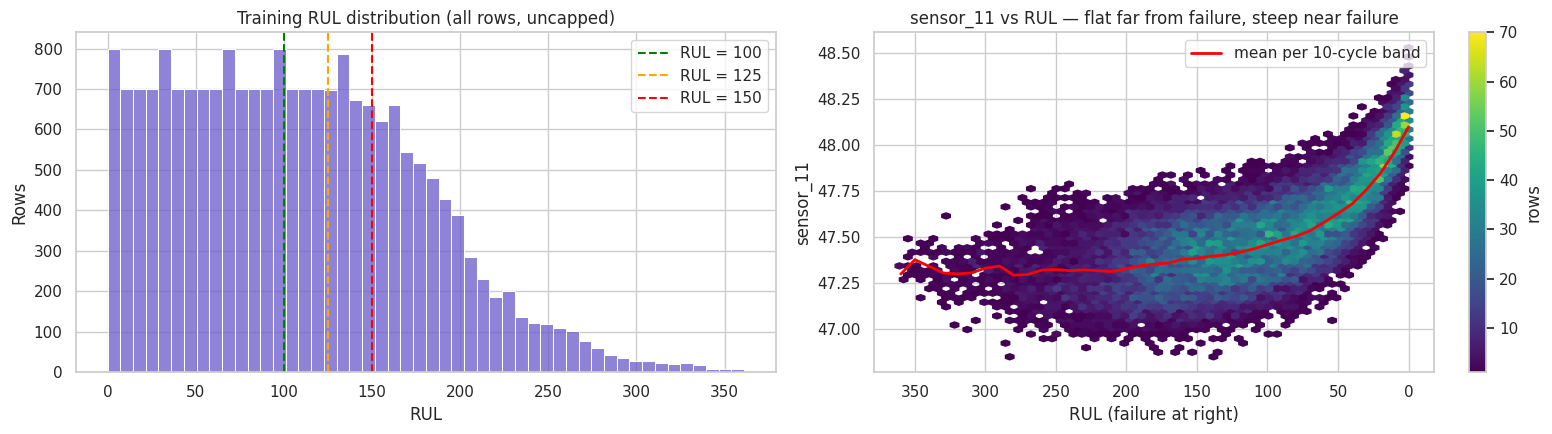

In [15]:
# Cell 14 — Distribution of the (uncapped) training RUL target
print(eda["RUL"].describe().round(1))
for t in (100, 125, 150):
    print(f"Share of rows with RUL > {t}: {(eda['RUL'] > t).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(eda["RUL"], bins=50, ax=axes[0], color="slateblue")
for t, c in zip((100, 125, 150), ("green", "orange", "red")):
    axes[0].axvline(t, color=c, ls="--", label=f"RUL = {t}")
axes[0].set(title="Training RUL distribution (all rows, uncapped)", xlabel="RUL", ylabel="Rows")
axes[0].legend()

hb = axes[1].hexbin(eda["RUL"], eda["sensor_11"], gridsize=60, cmap="viridis", mincnt=1)
band_mean = eda.groupby(eda["RUL"] // 10 * 10)["sensor_11"].mean()
axes[1].plot(band_mean.index, band_mean.values, color="red", lw=2, label="mean per 10-cycle band")
axes[1].invert_xaxis()
axes[1].set(title="sensor_11 vs RUL — flat far from failure, steep near failure",
            xlabel="RUL (failure at right)", ylabel="sensor_11")
axes[1].legend(); fig.colorbar(hb, ax=axes[1], label="rows")
fig.tight_layout(); save_fig(fig, "10_rul_distribution"); plt.show()

In [16]:
# Cell 15 — Persist EDA conclusions for Phase 3 (documentation, not yet decisions)
findings = {
    "dataset": FD,
    "constant_features": var_df.index[var_df["flag"] == "CONSTANT"].tolist(),
    "near_constant_features": var_df.index[var_df["flag"] == "NEAR-CONSTANT"].tolist(),
    "variable_features": VARIABLE,
    "n_operating_regimes": int(len(regimes)),
    "corr_with_rul_pearson": rul_corr["pearson"].round(4).to_dict(),
    "highly_correlated_pairs": [[a, b, float(r)] for a, b, r in pairs],
    "train_lifetime_min_max": [int(train_life.min()), int(train_life.max())],
    "test_observed_length_min": int(test_obs.min()),
    "share_rows_rul_gt_125": round(float((eda["RUL"] > 125).mean()), 4),
}
with open(TAB_DIR / "eda_findings.json", "w") as f:
    json.dump(findings, f, indent=2) if "json" in dir() else __import__("json").dump(findings, f, indent=2)
print(json.dumps(findings, indent=2) if "json" in dir() else findings)

{'dataset': 'FD001', 'constant_features': ['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19'], 'near_constant_features': ['sensor_6'], 'variable_features': ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'], 'n_operating_regimes': 1, 'corr_with_rul_pearson': {'sensor_11': -0.6962, 'sensor_4': -0.6789, 'sensor_15': -0.6427, 'sensor_2': -0.6065, 'sensor_17': -0.6062, 'sensor_3': -0.5845, 'sensor_8': -0.564, 'sensor_13': -0.5626, 'sensor_9': -0.3901, 'sensor_14': -0.3068, 'op_setting_1': -0.0032, 'op_setting_2': -0.0019, 'sensor_20': 0.6294, 'sensor_21': 0.6357, 'sensor_7': 0.6572, 'sensor_12': 0.672}, 'highly_correlated_pairs': [['sensor_4', 'sensor_11', 0.83], ['sensor_4', 'sensor_12', -0.816], ['sensor_7', 'sensor_11', -0.823], ['sensor_7', 'sensor_12', 0.813], ['sensor_8', 'sensor_13', 0.8